In [1]:
import math
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader, Subset, ConcatDataset

from torchvision import datasets, transforms

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [2]:
class TimeEmbed(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(1, dim),
            nn.SiLU(),
            nn.Linear(dim, dim)
        )

    def forward(self, t):
        return self.mlp(t[:, None])

class Block(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_emb = nn.Linear(t_dim, out_ch)

    def forward(self, x, t):
        h = F.silu(self.conv1(x))
        h = h + self.time_emb(t)[:, :, None, None]
        h = F.silu(self.conv2(h))
        return h

class DoubleStandardClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        base = 32
        t_dim = 32

        self.time_embed = TimeEmbed(t_dim)

        self.down1 = Block(1, base, t_dim)
        self.down2 = Block(base, base * 2, t_dim)
        self.down3 = Block(base * 2, base * 2, t_dim)
        self.pool = nn.MaxPool2d(2)

        self.mid = Block(base * 2, base * 2, t_dim)

        self.out = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(base * 2, 2)
        )
        
    def forward(self, x, t):
        t = self.time_embed(t)

        d1 = self.down1(x, t)
        d2 = self.down2(self.pool(d1), t)
        d3 = self.down3(self.pool(d2), t)

        m = self.mid(d3, t)

        return self.out(m)

class SingleStandardClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        base = 22
        t_dim = 32

        self.time_embed = TimeEmbed(t_dim)

        self.down1 = Block(1, base, t_dim)
        self.down2 = Block(base, base * 2, t_dim)
        self.down3 = Block(base * 2, base * 2, t_dim)
        self.pool = nn.MaxPool2d(2)

        self.mid = Block(base * 2, base * 2, t_dim)

        self.out = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(base * 2, 2)
        )
        
    def forward(self, x, t):
        t = self.time_embed(t)

        d1 = self.down1(x, t)
        d2 = self.down2(self.pool(d1), t)
        d3 = self.down3(self.pool(d2), t)

        m = self.mid(d3, t)

        return self.out(m)

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 30)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

patternClassifier = SingleStandardClassifier().to(device)
clothesClassifier = SingleStandardClassifier().to(device)
doubleClassifier = DoubleStandardClassifier().to(device)
cls = Classifier().to(device)
uNet = UNet().to(device)

patternClassifier.eval()
clothesClassifier.eval()
doubleClassifier.eval()
cls.eval()
uNet.eval()

# doubleClassifier.load_state_dict(torch.load("single_dre.pth", map_location=device))
# clothesClassifier.load_state_dict(torch.load("duo_type_dre.pth", map_location=device))
# patternClassifier.load_state_dict(torch.load("duo_patt_dre.pth", map_location=device))

cls.load_state_dict(torch.load("fashion_pattern_mnist_cnn.pth", map_location=device))
uNet.load_state_dict(torch.load("diffusion.pth", map_location=device))

img_size = 28
batch_size = 128
epochs = 100
timesteps = 500

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [4]:
addition_whole = []
for s in [1]:
    # n_samples = 500
    n_samples = 100
    addition = []
    
    for j in range(5):
    # for j in range(1):
        # doubleClassifier.load_state_dict(torch.load(f"Training DRES/CloPat DRE/best_CloPat_{i}.pt", map_location=device))
        clothesClassifier.load_state_dict(torch.load(f"Training DRES/clothes DRE/best_clothes_{j}.pt", map_location=device))
        patternClassifier.load_state_dict(torch.load(f"Training DRES/pattern DRE/best_pattern_{j}.pt", map_location=device))
    
        addition_outputs = []
        with torch.no_grad():
            xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
            
            for i in reversed(range(timesteps)):
                t = torch.tensor([i] * n_samples, device=device)
                
                eps_pred = uNet(xt, t.float() / timesteps)
                
                alpha_t = alpha[i]
                alpha_bar_t = alpha_bar[i]
                beta_t = beta[i]
        
                mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)
        
                with torch.enable_grad():
                    dre_xt = xt.detach().clone().requires_grad_(True)
                    
                    logits = clothesClassifier(dre_xt, t.float() / timesteps) 
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    r = log_probs[:, 1] - log_probs[:, 0]
                    
                    pattern_guide_score = torch.autograd.grad(
                        outputs=r.sum(),
                        inputs=dre_xt
                    )[0]
    
                with torch.enable_grad():
                    dre_xt = xt.detach().clone().requires_grad_(True)
                    
                    logits = patternClassifier(dre_xt, t.float() / timesteps)
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    r = log_probs[:, 1] - log_probs[:, 0]
                    
                    shape_guide_score = torch.autograd.grad(
                        outputs=r.sum(),
                        inputs=dre_xt
                    )[0]
                mean = mean + s * beta_t * (pattern_guide_score + shape_guide_score)
                
                if i > 0:
                    noise = torch.randn_like(xt)
                    xt = mean + torch.sqrt(beta_t) * noise
                else:
                    xt = mean
            print("s: {} complete", s)
            addition_outputs.append((s, xt))
        addition.append(addition_outputs)
    addition_whole.append((s, addition))

s: {} complete 1
s: {} complete 1
s: {} complete 1
s: {} complete 1
s: {} complete 1


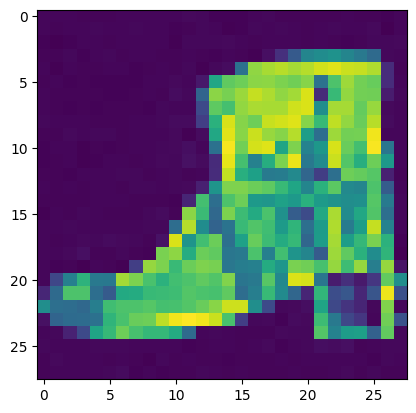

In [91]:
_, a = addition_whole[0]
_, b = a[0][0]
plt.imshow(b[5, 0].cpu())

In [92]:
_, a = addition_whole[0]
_, b = a[0][0]

In [93]:
cls(b).softmax(dim=1).mean(dim=0)

tensor([1.0318e-02, 1.2102e-04, 1.0540e-03, 1.3043e-03, 5.9811e-04, 6.5862e-02,
        2.9266e-03, 2.1880e-01, 1.1427e-02, 4.2589e-01, 1.0505e-04, 4.8729e-06,
        7.0995e-06, 2.1669e-05, 1.8013e-05, 1.6481e-02, 9.6570e-06, 1.9576e-02,
        1.6712e-03, 3.1306e-02, 1.9231e-04, 1.5306e-05, 4.2760e-05, 5.8625e-05,
        6.9983e-05, 2.3813e-02, 5.4110e-05, 6.3651e-02, 1.5715e-03, 1.0302e-01],
       device='cuda:0', grad_fn=<MeanBackward1>)

<BarContainer object of 30 artists>

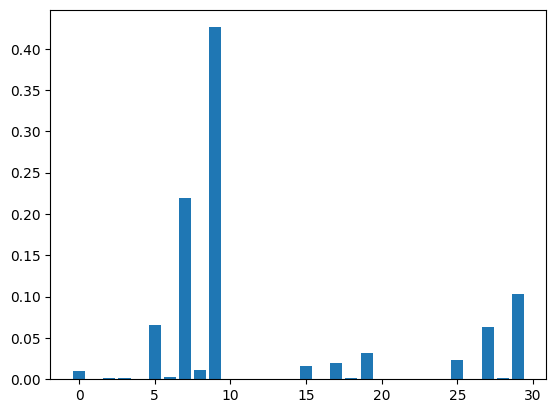

In [94]:
plt.bar(list(range(30)), cls(b).softmax(dim=1).mean(dim=0).cpu().detach())

In [96]:
addition_whole = []
for s in [1]:
    # n_samples = 500
    n_samples = 100
    addition = []
    
    for j in range(5):
    # for j in range(1):
        # doubleClassifier.load_state_dict(torch.load(f"Training DRES/CloPat DRE/best_CloPat_{i}.pt", map_location=device))
        clothesClassifier.load_state_dict(torch.load(f"Training DRES/clothes DRE/best_clothes_{j}.pt", map_location=device))
        patternClassifier.load_state_dict(torch.load(f"Training DRES/pattern DRE/best_pattern_{j}.pt", map_location=device))
    
        addition_outputs = []
        with torch.no_grad():
            xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
            
            for i in reversed(range(timesteps)):
                t = torch.tensor([i] * n_samples, device=device)
                
                eps_pred = uNet(xt, t.float() / timesteps)
                
                alpha_t = alpha[i]
                alpha_bar_t = alpha_bar[i]
                beta_t = beta[i]
        
                mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)
        
                with torch.enable_grad():
                    dre_xt = xt.detach().clone().requires_grad_(True)
                    
                    logits = clothesClassifier(dre_xt, t.float() / timesteps) 
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    r = log_probs[:, 1] - log_probs[:, 0]
                    
                    pattern_guide_score = torch.autograd.grad(
                        outputs=r.sum(),
                        inputs=dre_xt
                    )[0]
    
                with torch.enable_grad():
                    dre_xt = xt.detach().clone().requires_grad_(True)
                    
                    logits = patternClassifier(dre_xt, t.float() / timesteps)
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    r = log_probs[:, 1] - log_probs[:, 0]
                    
                    shape_guide_score = torch.autograd.grad(
                        outputs=r.sum(),
                        inputs=dre_xt
                    )[0]
                mean = mean + s * beta_t * (pattern_guide_score + 0.5 * shape_guide_score)
                
                if i > 0:
                    noise = torch.randn_like(xt)
                    xt = mean + torch.sqrt(beta_t) * noise
                else:
                    xt = mean
            print("s: {} complete", s)
            addition_outputs.append((s, xt))
        addition.append(addition_outputs)
    addition_whole.append((s, addition))

s: {} complete 1
s: {} complete 1
s: {} complete 1
s: {} complete 1
s: {} complete 1


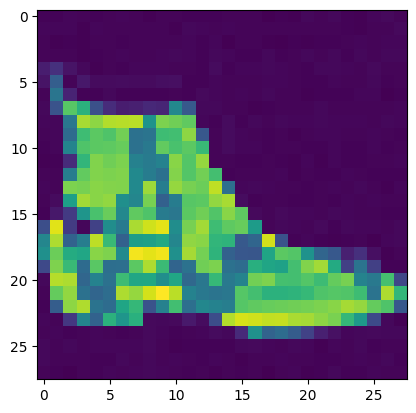

In [97]:
_, a = addition_whole[0]
_, b = a[0][0]
plt.imshow(b[5, 0].cpu())

In [98]:
cls(b).softmax(dim=1).mean(dim=0)

tensor([1.2144e-02, 1.5002e-04, 4.1952e-04, 1.5597e-02, 3.0014e-04, 7.6075e-02,
        9.6300e-04, 2.0019e-01, 2.3599e-02, 3.3063e-01, 5.4979e-04, 3.9684e-05,
        9.8560e-05, 2.3902e-04, 9.4826e-05, 1.8188e-02, 8.3910e-05, 5.9406e-02,
        2.2771e-03, 3.8272e-02, 3.0387e-03, 5.2241e-04, 1.1337e-03, 9.9306e-03,
        7.1566e-04, 3.8064e-02, 1.1052e-03, 7.2943e-02, 1.5477e-03, 9.1683e-02],
       device='cuda:0', grad_fn=<MeanBackward1>)

<BarContainer object of 30 artists>

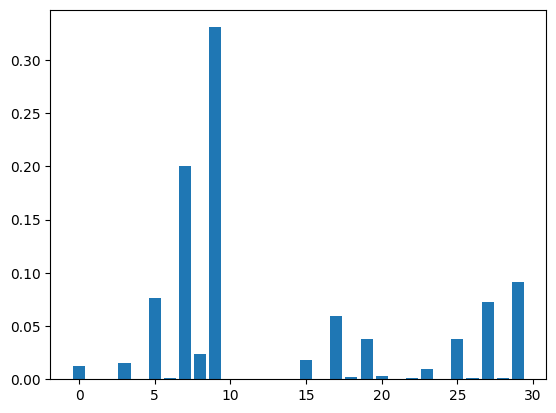

In [99]:
plt.bar(list(range(30)), cls(b).softmax(dim=1).mean(dim=0).cpu().detach())